In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib
import matplotlib.pyplot as plt
%config InlineBackend.figure_formats = ['svg']
matplotlib.rcParams['lines.linewidth'] = 2
matplotlib.rcParams['font.family'] = "sans-serif"
matplotlib.rcParams['legend.fontsize'] = 12
matplotlib.rcParams['axes.labelsize'] = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12
matplotlib.rcParams['legend.title_fontsize'] = 12
matplotlib.rcParams['axes.spines.top'] = False
matplotlib.rcParams['axes.spines.right'] = False
matplotlib.rcParams['figure.dpi'] = 250
matplotlib.rcParams['figure.figsize'] = (4,3)
cmap = plt.get_cmap("viridis")

## Define Model (MLP on Fashion MNIST)

In [2]:

# Loading a subset of fashion MNIST
selected_classes = [0, 1, 2]
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
full_train_dataset = datasets.FashionMNIST(root='./data', train=True, transform=transform, download=True)
full_test_dataset = datasets.FashionMNIST(root='./data', train=False, transform=transform, download=True)
def filter_by_classes(dataset, classes):
    indices = [i for i, (_, label) in enumerate(dataset) if label in classes]
    subset = Subset(dataset, indices)
    return subset
train_dataset = filter_by_classes(full_train_dataset, selected_classes)
test_dataset = filter_by_classes(full_test_dataset, selected_classes)

# Define a simple MLP
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28*28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 3)

    def forward(self, x):
        x = x.view(-1, 28*28)  # Flatten the 28x28 image
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x


100.0%
100.0%
100.0%
100.0%


## Training loop

In [3]:
def train(eta,bs):

  # define model
  model = MLP()
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=eta)

  #define batch size
  train_loader = DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True)
  test_loader = DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False)

  #variables to put in accuracies
  training_losses = []
  training_accuracies = []
  test_losses = []
  test_accuracies = []
  num_epochs = 30

  # Training loop
  for epoch in range(num_epochs):
      model.train()
      epoch_train_loss = 0
      epoch_train_correct = 0
      total_train_samples = 0

      for i, (images, labels) in enumerate(train_loader):
          # Forward pass
          outputs = model(images)
          loss = criterion(outputs, labels)

          # Calculate accuracy
          _, predicted = torch.max(outputs.data, 1)
          correct = (predicted == labels).sum().item()

          # Backward and optimize
          optimizer.zero_grad()
          loss.backward()
          optimizer.step()

          # Accumulate epoch-level stats
          epoch_train_loss += loss.item() * labels.size(0)
          epoch_train_correct += correct
          total_train_samples += labels.size(0)

      # Calculate and store epoch-level training loss and accuracy
      epoch_train_loss /= total_train_samples
      epoch_train_accuracy = epoch_train_correct / total_train_samples
      training_losses.append(epoch_train_loss)
      training_accuracies.append(epoch_train_accuracy)

      print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {epoch_train_loss:.4f}, Training Accuracy: {epoch_train_accuracy * 100:.2f}%')

      # Testing loop at each epoch
      model.eval()
      epoch_test_loss = 0
      epoch_test_correct = 0
      total_test_samples = 0

      with torch.no_grad():
          for images, labels in test_loader:
              outputs = model(images)
              loss = criterion(outputs, labels)

              # Calculate accuracy
              _, predicted = torch.max(outputs.data, 1)
              correct = (predicted == labels).sum().item()

              # Accumulate epoch-level stats
              epoch_test_loss += loss.item() * labels.size(0)
              epoch_test_correct += correct
              total_test_samples += labels.size(0)

      # Calculate and store epoch-level test loss and accuracy
      epoch_test_loss /= total_test_samples
      epoch_test_accuracy = epoch_test_correct / total_test_samples
      test_losses.append(epoch_test_loss)
      test_accuracies.append(epoch_test_accuracy)

      print(f'Epoch [{epoch+1}/{num_epochs}], Test Loss: {epoch_test_loss:.4f}, Test Accuracy: {epoch_test_accuracy * 100:.2f}%')
  return training_losses, training_accuracies, test_losses,test_accuracies

In [13]:
batch_sizes = [16, 32, 64, 128]
learning_rates = [0.01, 0.02, 0.04, 0.16]
results = {}

for learning_rate in learning_rates:
    for batch_size in batch_sizes:
        results[learning_rate, batch_size] = train(learning_rate, batch_size)

Epoch [1/30], Training Loss: 0.2187, Training Accuracy: 93.54%
Epoch [1/30], Test Loss: 0.1347, Test Accuracy: 95.37%
Epoch [2/30], Training Loss: 0.1086, Training Accuracy: 96.44%
Epoch [2/30], Test Loss: 0.1132, Test Accuracy: 96.23%
Epoch [3/30], Training Loss: 0.0968, Training Accuracy: 96.86%
Epoch [3/30], Test Loss: 0.1045, Test Accuracy: 96.50%
Epoch [4/30], Training Loss: 0.0890, Training Accuracy: 97.13%
Epoch [4/30], Test Loss: 0.0990, Test Accuracy: 96.53%
Epoch [5/30], Training Loss: 0.0838, Training Accuracy: 97.18%
Epoch [5/30], Test Loss: 0.0961, Test Accuracy: 96.57%
Epoch [6/30], Training Loss: 0.0794, Training Accuracy: 97.27%
Epoch [6/30], Test Loss: 0.0936, Test Accuracy: 96.67%
Epoch [7/30], Training Loss: 0.0753, Training Accuracy: 97.49%
Epoch [7/30], Test Loss: 0.0954, Test Accuracy: 96.80%
Epoch [8/30], Training Loss: 0.0727, Training Accuracy: 97.60%
Epoch [8/30], Test Loss: 0.0892, Test Accuracy: 96.80%
Epoch [9/30], Training Loss: 0.0689, Training Accuracy: 

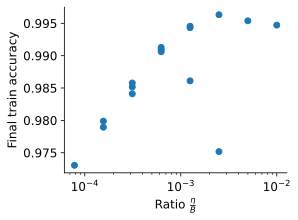

In [ ]:
ratios = [learning_rate / batch_size for learning_rate in learning_rates for batch_size in batch_sizes]
final_train_losses = [results[learning_rate, batch_size][1][-1] for learning_rate in learning_rates for batch_size in batch_sizes]

plt.scatter(ratios, final_train_losses)
plt.xlabel("Ratio " + r"$\frac{\eta}{B}$")
plt.xscale("log")
plt.ylabel("Final train accuracy")
plt.show()